# 🎬 Sentiment Analysis of Movie Reviews using Deep Learning (LSTM)

### TCIE-1 Individual Deep Learning Project

**Goal:** Classify a movie review as **Positive** or **Negative** using an LSTM Deep Learning model and provide a **one-screen desktop application** for live prediction.

**Dataset:** IMDB Movie Reviews (25,000 training + 25,000 testing reviews)

**Technologies:** Python, TensorFlow/Keras, NumPy, Matplotlib, Scikit-learn, Tkinter


## 1. Problem Statement

People write a large number of movie reviews online. Manually checking every review is time-consuming. This project uses Deep Learning with an LSTM neural network to automatically predict whether a movie review is positive or negative.


## 2. Dataset Description

The project uses the IMDB Movie Reviews dataset through `tensorflow.keras.datasets.imdb`.

- 25,000 training reviews
- 25,000 testing reviews
- Label `0` = Negative
- Label `1` = Positive
- Top 10,000 most frequent words are used
- Each review is padded/truncated to 200 words


In [1]:
# Check the Python environment
import sys
print("Python executable:", sys.executable)
print("Python version:", sys.version)

# If TensorFlow is not installed, install it from the VS Code Terminal:
# python -m pip install tensorflow==2.21.0 numpy pandas matplotlib seaborn scikit-learn ipykernel


Python executable: c:\Users\Anand\AppData\Local\Programs\Python\Python313\python.exe
Python version: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)


All libraries imported successfully!
TensorFlow version: 2.21.0


## 3. Load the IMDB Dataset


In [3]:
MAX_WORDS = 10000
MAX_LENGTH = 200

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=MAX_WORDS)

print("Training reviews:", len(X_train))
print("Testing reviews :", len(X_test))
print("First training label:", y_train[0])
print("First review encoded length:", len(X_train[0]))


Training reviews: 25000
Testing reviews : 25000
First training label: 1
First review encoded length: 218


## 4. Prepare the Data

Neural networks require input sequences of equal length. `pad_sequences()` makes every review exactly 200 tokens long.


In [4]:
X_train = pad_sequences(X_train, maxlen=MAX_LENGTH)
X_test = pad_sequences(X_test, maxlen=MAX_LENGTH)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)


X_train shape: (25000, 200)
X_test shape : (25000, 200)


## 5. LSTM Model Architecture

**Workflow:**

`Movie Review → Tokenized Sequence → Padding → Embedding → LSTM → Dropout → Dense → Sigmoid → Positive/Negative`


In [5]:
model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=128, input_length=MAX_LENGTH),
    LSTM(64),
    Dropout(0.5),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


c:\Users\Anand\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 6. Train the Deep Learning Model

3 epochs are used to keep the lab demonstration manageable. You can change `epochs=3` to `epochs=5` if required.


In [6]:
history = model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.20,
    verbose=1
)


Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 28s 77ms/step - accuracy: 0.7896 - loss: 0.4360 - val_accuracy: 0.8604 - val_loss: 0.3230
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 72ms/step - accuracy: 0.9022 - loss: 0.2552 - val_accuracy: 0.8660 - val_loss: 0.3127
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 23s 72ms/step - accuracy: 0.9313 - loss: 0.1806 - val_accuracy: 0.8490 - val_loss: 0.3542


## 7. Training and Validation Accuracy


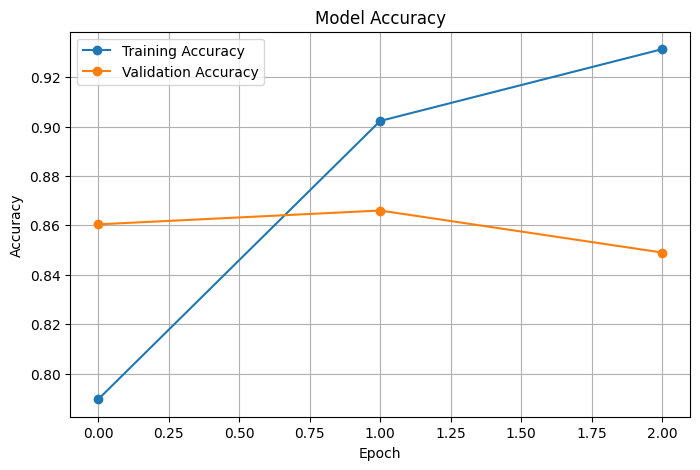

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


## 8. Training and Validation Loss


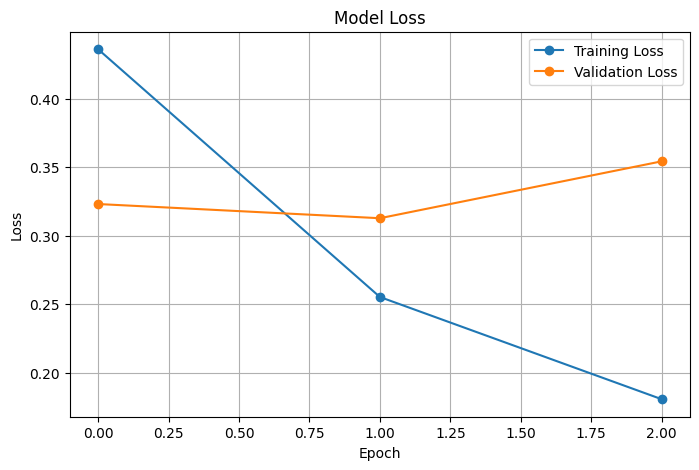

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


## 9. Evaluate the Model on Test Data


In [9]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


Test Loss: 0.3580
Test Accuracy: 85.29%


## 10. Confusion Matrix and Classification Report


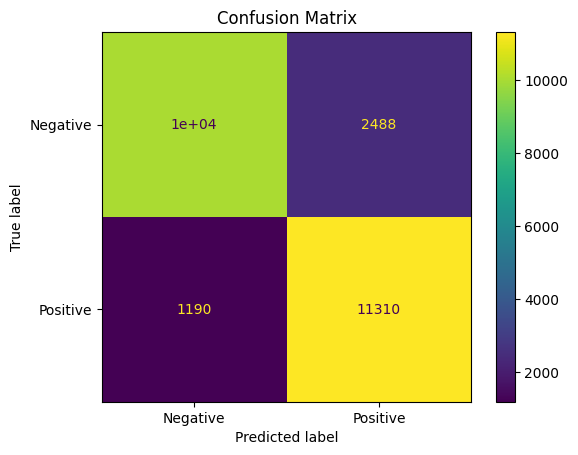

              precision    recall  f1-score   support

    Negative       0.89      0.80      0.84     12500
    Positive       0.82      0.90      0.86     12500

    accuracy                           0.85     25000
   macro avg       0.86      0.85      0.85     25000
weighted avg       0.86      0.85      0.85     25000



In [10]:
y_pred_probability = model.predict(X_test, verbose=0)
y_pred = (y_pred_probability >= 0.5).astype("int32").ravel()

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)
disp.plot()
plt.title("Confusion Matrix")
plt.show()

print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))


## 11. Convert User Text into Model Input

The IMDB dataset uses integer word IDs. This function converts normal English text into the same type of sequence used during training.


In [11]:
word_index = imdb.get_word_index()

def encode_user_review(text):
    words = text.lower().split()
    encoded = [word_index.get(word, 2) + 3 for word in words]
    return pad_sequences([encoded], maxlen=MAX_LENGTH)

def predict_sentiment(text):
    if not text.strip():
        return "Please enter a review.", 0.0

    input_data = encode_user_review(text)
    probability = float(model.predict(input_data, verbose=0)[0][0])

    if probability >= 0.5:
        return "Positive", probability * 100
    else:
        return "Negative", (1 - probability) * 100

sentiment, confidence = predict_sentiment(
    "This movie was amazing and I really enjoyed it"
)
print("Example prediction:", sentiment)
print("Confidence:", f"{confidence:.2f}%")


Example prediction: Positive
Confidence: 90.67%


# 🖥️ 12. One-Screen Desktop Application

Run the next cell to open the desktop application. Enter any movie review and click **ANALYZE SENTIMENT**.

The application uses Python's built-in **Tkinter** library.


In [ ]:
import tkinter as tk
from tkinter import messagebox

def launch_desktop_app():
    root = tk.Tk()
    root.title("Movie Sentiment Analyzer - Deep Learning")
    root.geometry("850x600")
    root.resizable(False, False)

    tk.Label(
        root,
        text="🎬 MOVIE SENTIMENT ANALYZER",
        font=("Arial", 24, "bold")
    ).pack(pady=(25, 5))

    tk.Label(
        root,
        text="Deep Learning • LSTM Model • IMDB Movie Reviews",
        font=("Arial", 12)
    ).pack(pady=(0, 20))

    tk.Label(
        root,
        text="Enter your movie review:",
        font=("Arial", 14, "bold")
    ).pack(anchor="w", padx=70)

    review_box = tk.Text(
        root,
        height=8,
        width=78,
        font=("Arial", 12),
        wrap="word"
    )
    review_box.pack(padx=70, pady=10)

    result_var = tk.StringVar(value="Result will appear here")
    tk.Label(
        root,
        textvariable=result_var,
        font=("Arial", 22, "bold")
    ).pack(pady=(20, 5))

    confidence_var = tk.StringVar(value="")
    tk.Label(
        root,
        textvariable=confidence_var,
        font=("Arial", 13)
    ).pack(pady=5)

    def analyze():
        text = review_box.get("1.0", "end").strip()

        if not text:
            messagebox.showwarning(
                "Input Required",
                "Please enter a movie review."
            )
            return

        sentiment, confidence = predict_sentiment(text)

        if sentiment == "Positive":
            result_var.set("😊  POSITIVE REVIEW")
        else:
            result_var.set("😞  NEGATIVE REVIEW")

        confidence_var.set(
            f"Model Confidence: {confidence:.2f}%"
        )

    def clear_review():
        review_box.delete("1.0", "end")
        result_var.set("Result will appear here")
        confidence_var.set("")

    button_frame = tk.Frame(root)
    button_frame.pack(pady=15)

    tk.Button(
        button_frame,
        text="ANALYZE SENTIMENT",
        command=analyze,
        font=("Arial", 13, "bold"),
        padx=20,
        pady=10
    ).grid(row=0, column=0, padx=10)

    tk.Button(
        button_frame,
        text="CLEAR",
        command=clear_review,
        font=("Arial", 13, "bold"),
        padx=30,
        pady=10
    ).grid(row=0, column=1, padx=10)

    tk.Label(
        root,
        text="Powered by TensorFlow / Keras LSTM",
        font=("Arial", 10)
    ).pack(side="bottom", pady=15)

    root.mainloop()

launch_desktop_app()


## 13. Sample Reviews for Demonstration

**Positive:** `This movie was fantastic, emotional and entertaining. I loved every minute of it.`

**Negative:** `This movie was boring, poorly written and a complete waste of time.`


## 14. Conclusion

The project demonstrates how Deep Learning and an LSTM network can be used for binary sentiment classification of movie reviews. The trained model learns patterns in review text and predicts whether a new review is positive or negative. The one-screen Tkinter desktop interface makes the project easy to demonstrate in the lab.
